# The 97 published blasts, the sixteen cases and the committed artifacts

**Level 1: Fundamentals** · Needs: nothing, this is the entry notebook · Reading time: about 15 minutes

## Objectives

Fragmenta predicts the mean fragment size `x50` of a bench blast, and measures what each prediction is worth at a mine the model has not seen. Everything it shows rests on one small table of real measurements. This notebook opens that table.

By the end you will have:

- loaded the 97 published blasts with the engine and read the seven numbers that describe each one;
- seen how the blasts group into ten campaigns (sites), which is the unit that every later notebook holds out;
- listed the sixteen cases the product is built on and opened one committed artifact to see what the bake wrote.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

Three sources, all read from files, none typed:

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97-blast training corpus and the hold-outs | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article is copyrighted and never ships | the table inside the `blastfrag` wheel, read by `bf.load_training_corpus()` |
| The case index | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/manifests/index.json` |
| One case artifact | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/real-enusa/case.json` |

The corpus is dimensionless: each blast is recorded as ratios (spacing over burden, bench height over burden, burden over hole diameter, stemming over burden), a powder factor, the in situ block size and the rock modulus, plus the measured `x50`.

## Method

### Step 1: imports and paths

The cell below imports the engine and fixes the path to the committed artifacts. The notebook runs from its own folder, so the repository root is three levels up; no absolute path is ever written.

In [2]:
# The engine, plain numerics and the plotting library
import json
from collections import defaultdict
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

# The committed artifacts, relative to the repository root
DERIVED = Path("../../../data/derived")

### Step 2: load the corpus

`load_training_corpus()` returns the 97 blasts as immutable `Blast` records. Loading also runs the integrity gate (notebook 03 of this topic opens it): the call fails if a row no longer reproduces the descriptive statistics the paper prints.

In [3]:
# Load the 97 blasts (the integrity gate runs inside the call)
train = bf.load_training_corpus()
print("blasts:", len(train))
print("inputs, in the order every published equation uses:", bf.FEATURES)
first = train[0]
print("first blast:", first.blast_id, first.site)
for name in bf.FEATURES:
    print(f"  {name:>9} = {getattr(first, name)}")
print(f"  {'x50_m':>9} = {first.x50_m}  (measured, metres)")

blasts: 97
inputs, in the order every published equation uses: ('S_over_B', 'H_over_B', 'B_over_D', 'T_over_B', 'Pf_kg_m3', 'XB_m', 'E_GPa')
first blast: En1 Enusa
   S_over_B = 1.24
   H_over_B = 1.33
   B_over_D = 27.27
   T_over_B = 0.78
   Pf_kg_m3 = 0.48
       XB_m = 0.58
      E_GPa = 60.0
      x50_m = 0.37  (measured, metres)


### Step 3: the ten campaigns

Rows that share a campaign share a rock mass, a rig, an explosive supply and a measurement operator, so they are not independent draws. This is the structural fact behind the whole product, and the table makes it concrete: one quarry supplies 22 of the 97 rows.

In [4]:
# Group the blasts by site and summarise the measured mean size of each campaign
by_site = defaultdict(list)
for blast in train:
    by_site[blast.site].append(blast)

print(f"{'site':<14}{'n':>3}{'mean x50 (m)':>18}{'min':>8}{'max':>8}")
for site in sorted(by_site, key=lambda s: -len(by_site[s])):
    sizes = np.array([b.x50_m for b in by_site[site]])
    print(f"{site:<14}{len(sizes):>3}{sizes.mean():>18.3f}{sizes.min():>8.2f}{sizes.max():>8.2f}")

site            n      mean x50 (m)     min     max
Akdaglar       22             0.171    0.14    0.22
Enusa          12             0.396    0.26    0.64
Mrica          11             0.166    0.13    0.21
Reocin         10             0.616    0.44    0.96
Dongri-Buzurg   9             0.413    0.23    0.76
Murgul          7             0.311    0.23    0.38
Soma            7             0.224    0.15    0.28
Ozmert          7             0.191    0.12    0.30
Reocin-UG       6             0.593    0.51    0.69
Miami           6             0.080    0.02    0.10


The next cell draws the same ten campaigns as a strip plot of the measured `x50`, one dot per blast, so the between-site differences can be compared with the within-site scatter.

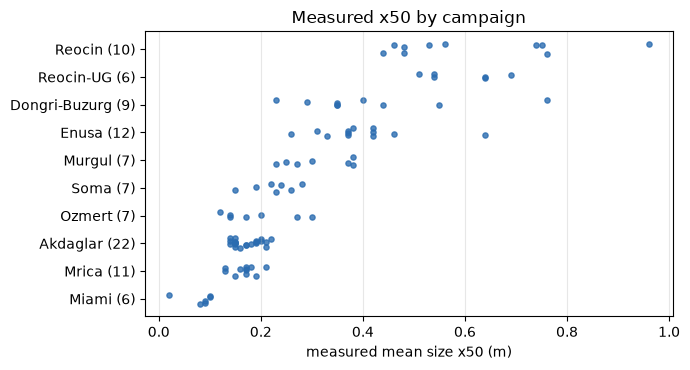

In [5]:
# One row of dots per site, ordered by the site's mean size
order = sorted(by_site, key=lambda s: np.mean([b.x50_m for b in by_site[s]]))
fig, ax = plt.subplots(figsize=(7, 3.8))
rng = np.random.default_rng(0)
for row, site in enumerate(order):
    sizes = [b.x50_m for b in by_site[site]]
    ax.scatter(sizes, row + rng.uniform(-0.18, 0.18, len(sizes)), s=14, color="#2b6cb0", alpha=0.8)
ax.set_yticks(range(len(order)), [f"{s} ({len(by_site[s])})" for s in order])
ax.set_xlabel("measured mean size x50 (m)")
ax.set_title("Measured x50 by campaign")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

### Step 4: the envelope of the inputs

A model fitted on this table is only trusted inside the ranges the table covers. `envelope_report` states each input's range on the 97 rows and checks it against the envelope the engine declares (`TRAINING_ENVELOPE`).

In [6]:
# The range of each input on the corpus, and how many rows fall outside the declared envelope
report = bf.envelope_report(train)
print(f"{'input':<10}{'min':>8}{'max':>8}{'mean':>8}{'outside':>9}")
for name, stat in report.items():
    print(f"{name:<10}{stat['min']:>8.2f}{stat['max']:>8.2f}{stat['mean']:>8.2f}{stat['n_outside_envelope']:>9}")

input          min     max    mean  outside
S_over_B      1.00    1.75    1.19        0
H_over_B      1.33    6.82    3.35        0
B_over_D     17.98   39.47   27.35        0
T_over_B      0.50    4.67    1.26        0
Pf_kg_m3      0.22    1.26    0.53        0
XB_m          0.02    2.35    1.11        0
E_GPa         9.57   60.00   29.46        0


### Step 5: the three hold-out sets

Besides the training corpus the engine ships two published validation sets (2010, 2012; they overlap) and five open-access field blasts from a granite mine whose modulus lies below the training minimum, so they are stamped as an extrapolation.

In [7]:
# The published hold-outs and the field set, with the modulus range of each
sets = {"2010": bf.load_holdout(protocol="2010"), "2012": bf.load_holdout(protocol="2012"),
        "field": bf.load_field_holdout()}
for name, blasts in sets.items():
    modulus = [b.E_GPa for b in blasts]
    print(f"{name:>8}: {len(blasts):>2} blasts, E = {min(modulus):.2f} to {max(modulus):.2f} GPa")
print("training minimum E:", min(b.E_GPa for b in train), "GPa")

    2010: 13 blasts, E = 9.57 to 60.00 GPa
    2012: 12 blasts, E = 9.57 to 60.00 GPa
   field:  5 blasts, E = 5.60 to 5.60 GPa
training minimum E: 9.57 GPa


### Step 6: the sixteen cases

A case is a coherent set of blasts that answers one question: ten real campaigns, one real out-of-envelope field set, and five synthetic designs (two of them controls). The bake wrote an index of all of them; the cell reads it and counts the cases by category.

In [8]:
# Read the committed index and count the cases by category
index = json.loads((DERIVED / "manifests" / "index.json").read_text(encoding="utf-8"))
counts = defaultdict(list)
for case in index["cases"]:
    counts[case["category"]].append(case["case_id"])
print("cases:", index["n_cases"], "| schema:", index["schema"], "| baked by app", index["app_version"])
for category, ids in counts.items():
    print(f"  {category:<24}{len(ids):>2}  {', '.join(ids)}")

cases: 16 | schema: fragmenta.index/v1 | baked by app 0.09.001
  negative-control         2  ctrl-degenerate, real-miami
  positive-control         1  ctrl-oracle
  real-campaign            9  real-akdaglar, real-dongri-buzurg, real-enusa, real-mrica, real-murgul, real-ozmert, real-reocin, real-reocin-ug, real-soma
  extrapolation-control    1  real-granite-ne
  structural-control       1  synth-ibsd-capped
  parameter-sweep          2  synth-sweep-burden, synth-sweep-powder


### Step 7: open one artifact

Each case has one artifact, `case.json`, which holds the blasts, the prediction of every arm (a number or a stated refusal), the scores and the provenance. The site never recomputes these documents; it replays them. The cell opens the Enusa case and checks that the artifact was baked from the same corpus the installed engine ships, by comparing digests.

In [9]:
# Open the Enusa artifact and compare its corpus digest with the one computed from the installed engine
artifact = json.loads((DERIVED / "real-enusa" / "case.json").read_text(encoding="utf-8"))
print("sections of the artifact:", sorted(artifact))
print("blasts in the case:", len(artifact["blasts"]))
print("arms with a prediction:", len(artifact["predictions"]))
print("engine that baked it:", artifact["provenance"]["engine"]["version"])
digest = bf.datasets.compute_dataset_digest(train)
print("same corpus as the installed engine:", artifact["provenance"]["corpus_digest"] == digest)

sections of the artifact: ['blasts', 'case', 'controls', 'digest', 'distributions', 'geometry_report', 'live_models', 'null_mean_m', 'predictions', 'provenance', 'representative_blast_id', 'schema', 'scores', 'variant_curves', 'variants']
blasts in the case: 12
arms with a prediction: 14
engine that baked it: 0.04.000
same corpus as the installed engine: True


## Results

**What the numbers show.** The corpus holds 97 blasts from ten campaigns in five countries. The campaigns are very unequal: one quarry supplies 22 rows and two campaigns supply only six, and the measured mean sizes differ between campaigns by more than the scatter inside most of them (the strip plot). That is why this product holds out whole campaigns rather than single blasts.

**What the envelope says.** All 97 rows sit inside the declared envelope, and the rock modulus runs from about 10 to 60 GPa. The five field blasts have a modulus of 5.6 GPa, below that minimum, so any prediction there is an extrapolation and is stamped as one.

**What the cases and the artifact say.** The sixteen cases are the questions the product answers; the artifact for one of them holds every arm's answer, and its corpus digest matches the digest computed from the installed engine, so the committed evidence and the engine describe the same 97 blasts.

**What this does not show.** Nothing here predicts or scores anything yet: the notebook only opens the data. It also says nothing about whether the numbers are correct against the paper; the integrity gate in notebook 03 of this topic does.

## Summary

- The engine loads the 97 published blasts in one call and checks them against the paper while loading.
- The blasts come from ten campaigns, and the campaign, not the blast, is the unit that carries dependence.
- Sixteen cases are indexed, and each has one committed artifact whose corpus digest ties it to the engine's corpus.
- Next: notebook 02 reconstructs absolute geometry from the ratios, which the classical equation needs.

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the 97-blast corpus and the first hold-out)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/